In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.options.display.max_columns = 500

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA

# Кластеризация

Наша задача - предсказать есть диабет у индивида или нет. В качестве таргета - колонка Diabetes. В нем три различных значения: `0`, `1`, `2`. `0` означает, что наблюдаемой здоров, `1` значит, что есть риск диабета, `2` означает наличие диабета. В качестве признаков будем использовать пол, количество лет в США, доход семьи и некоторые показатели, измеренные медицинскими работниками.  

**Задание 1.** В этой части ДЗ попробуем использовать кластеризацию как инструмент при проведении моделирования в задаче классификации

In [2]:
df = pd.read_csv('datahw21.csv', index_col='Unnamed: 0')

df.head()

,Gender,Years_in_US,Family_income,ArmCircum,SaggitalAbdominal,GripStrength,Breast_fed,Diabetes
0,1,0.0,0.84,35.3,20.6,55.2,2.0,2.0
1,1,0.0,1.78,34.7,24.4,61.5,2.0,2.0
2,1,0.0,4.51,33.5,25.6,91.0,2.0,2.0
3,1,0.0,2.52,21.0,14.9,32.2,2.0,0.0
4,2,0.0,5.00,25.2,20.7,30.9,2.0,0.0


<Axes: >

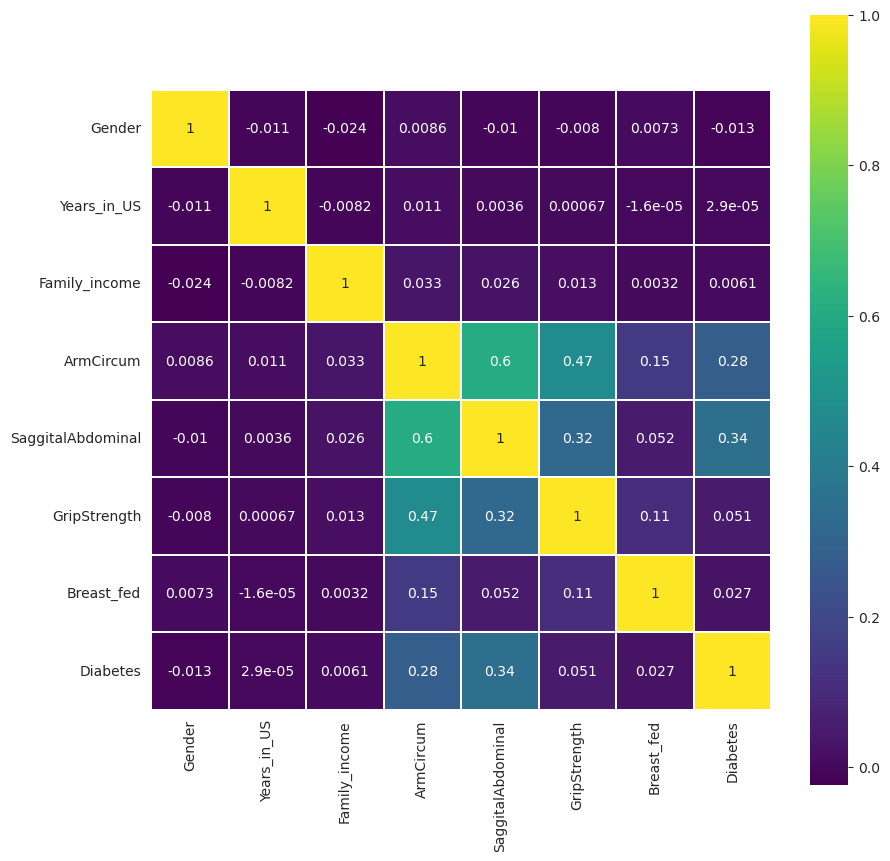

In [3]:
### Посмотрим как устроены данные
### Изобразим корреляционную матрицу

colormap = plt.cm.viridis
plt.figure(figsize=(10,10))
sns.heatmap(df.corr(), linewidths=0.1, vmax=1.0, square=True, cmap=colormap, annot=True)

In [4]:
### Разделим выборку на трейн-тест

data = df.drop(['Diabetes'], axis=1)
target = df[['Diabetes']]

X_train, X_test, y_train, y_test = train_test_split(data,
                                                    target, 
                                                    test_size=0.25,
                                                    random_state=1)

Для того, чтобы использовать K-means, лучше будет отнормировать данные. 

In [5]:
### Воспользуемся StandardScaler
from sklearn.preprocessing import StandardScaler
### Your code is here
X_train_scaled = StandardScaler().fit_transform(X_train)
X_test_scaled = StandardScaler().fit_transform(X_test)


Обучим K-Means с параметрами `n_clusters` = 3, `tol` = 0.0005. Выбор параметров обусловлен тем, что у нас три возможных значения таргета. Но в целом основной подход подбора количества кластеров - по кривой зависимости внутрикластерного и межкластерного расстояний от количества кластеров.

Установите `random_state` = 1

In [6]:
### Your code is here
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=3, random_state=1, tol=0.0005)
kmeans.fit(X_train_scaled)
y_pred = kmeans.predict(X_test_scaled)
from sklearn.metrics import accuracy_score
print(accuracy_score(y_test, y_pred))


0.37163814180929094


Посчитаем качество на изначальных данных(нормированных). Для этого обучите с дефолтными параметрами `RandomForestClassifier`, `LogisticRegression`, `LinearSVC`. Там, где нужно, установите `random_state` = 1. (1б)

In [7]:
### Your code is here
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

### Your code is here
rf = RandomForestClassifier(random_state=1).fit(X_train, y_train)
lr = LogisticRegression().fit(X_train, y_train)
svm = LinearSVC().fit(X_train, y_train)





In [9]:


print(f'Accuracy Леса: {round(accuracy_score(y_test, rf.predict(X_test)), 3)}')
print(f'Accuracy ЛогРега: {round(accuracy_score(y_test, lr.predict(X_test)), 3)}')
print(f'Accuracy Опорных векторов: {round(accuracy_score(y_test, svm.predict(X_test)), 3)}')



Accuracy Леса: 0.886
Accuracy ЛогРега: 0.89
Accuracy Опорных векторов: 0.892


Добавьте в признаковое описание номер кластера и посчитайте качество с новым признаком! Стало ли качество хоть сколько-то лучше? (1б)

In [13]:
### Your code is here
cols = X_train.columns
X_train_kms = pd.concat(
[pd.DataFrame(X_train_scaled, columns=cols), pd.DataFrame(kmeans.predict(X_train_scaled), columns=['Cluster'])], axis=1
)
    
X_test_kms = pd.concat(
[pd.DataFrame(X_test_scaled, columns=cols), pd.DataFrame(kmeans.predict(X_test_scaled), columns=['Cluster'])], axis=1
)

In [14]:
rf.fit(X_train_kms, y_train)
lr.fit(X_train_kms, y_train)
svm.fit(X_train_kms, y_train)

LinearSVC()

In [17]:


print(f'Accuracy Леса: {accuracy_score(y_test, rf.predict(X_test_kms))}')
print(f'Accuracy ЛогРега: {accuracy_score(y_test, lr.predict(X_test_kms))}')
print(f'Accuracy Опорных векторов: {accuracy_score(y_test, svm.predict(X_test_kms))}')



Accuracy Леса: 0.8895680521597392
Accuracy ЛогРега: 0.8883455582722086
Accuracy Опорных векторов: 0.8920130399348003


1Посчитаем расстояния от объектов до центров кластеров. Для этого воспользуемся методом `transform` обученного класса kmeans.

Обучим и посчитаем метрики исключительно на расстояниях до центра. Убедимся, что такой подход имеет право на существование, если данные позволяют, то качество не сильно должно пострадать. А в каких-то случаях может оказаться даже лучше! Таким образом можно снижать размерность данных. (2б)

In [18]:
### Your code is here
X_distances_train = kmeans.transform(X_train_scaled)
X_distances_test = kmeans.transform(X_test_scaled)

rf.fit(X_distances_train, y_train)
lr.fit(X_distances_train, y_train)
svm.fit(X_distances_train, y_train)

print(f'Accuracy Леса: {accuracy_score(y_test, rf.predict(X_distances_test))}')
print(f'Accuracy ЛогРега: {accuracy_score(y_test, lr.predict(X_distances_test))}')
print(f'Accuracy Опорных векторов: {accuracy_score(y_test, svm.predict(X_distances_test))}')



Accuracy Леса: 0.8838630806845966
Accuracy ЛогРега: 0.8920130399348003
Accuracy Опорных векторов: 0.8920130399348003
